# HW2：King County 房價預測 — 多元線性回歸 (Multiple Linear Regression)

- **資料集**：House Sales in King County, USA（Kaggle, harlfoxem）
- **連結**：https://www.kaggle.com/datasets/harlfoxem/housesalesprediction
- **內容**：美國華盛頓州 King County（含西雅圖）2014/05–2015/05 共 21,613 筆房屋成交紀錄，21 個欄位
- **流程**：CRISP-DM（Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment）

本程式只使用 numpy / pandas / scipy / scikit-learn / matplotlib / seaborn，
OLS 的標準誤、p-value、信賴區間與預測區間皆依公式自行計算，可在本機或 Google Colab 直接執行。

## 0. 環境設定

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.feature_selection import f_regression, RFE
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = "kc_house_data.csv"
FIG_DIR, OUT_DIR = "figures", "results"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_MAIN, C_ACC, C_BAND, C_GREY = "#2563EB", "#DC2626", "#93C5FD", "#6B7280"


def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name))
    plt.show()

## 1. Business Understanding

**商業問題**：房屋買賣雙方、仲介與估價師需要一個「可解釋」的房價估計工具：
給定一間房子的坪數、屋況、地點等條件，估計合理成交價，並給出**價格的可能範圍**（預測區間）。

**分析目標**
1. 以多元線性回歸預測房屋成交價 `price`。
2. 透過特徵選擇找出最關鍵的影響因子，讓模型精簡且可解釋。
3. 以 R²、Adjusted R²、RMSE、MAE、MAPE 與交叉驗證評估模型，並提供 95% 預測區間。

**成功標準**：測試集 R²（log 價格）≥ 0.75，且 95% 預測區間的實際涵蓋率接近 95%。

## 2. Data Understanding

In [2]:
if not os.path.exists(DATA_PATH):
    # 在 Colab 上可自動從 Kaggle 下載（需 kagglehub）
    try:
        import kagglehub
        path = kagglehub.dataset_download("harlfoxem/housesalesprediction")
        DATA_PATH = os.path.join(path, "kc_house_data.csv")
    except Exception as e:
        raise FileNotFoundError(
            "找不到 kc_house_data.csv，請從 Kaggle 下載後放在與本程式相同的資料夾。") from e

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

In [4]:
print("缺失值總數：", int(df.isnull().sum().sum()))
print("完全重複列：", int(df.duplicated().sum()))
print("重複 id（同一間房子成交兩次以上）：", int(df["id"].duplicated().sum()))
df.describe().T.round(2)

缺失值總數： 0
完全重複列： 0
重複 id（同一間房子成交兩次以上）： 177


,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1000102.00,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,75000.00,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370000e+00,9.300000e-01,0.00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.110000e+00,7.700000e-01,0.00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184400e+02,290.00,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,520.00,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.490000e+00,5.400000e-01,1.00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,1.000000e-02,9.000000e-02,0.00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.300000e-01,7.700000e-01,0.00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.410000e+00,6.500000e-01,1.00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


**欄位說明（扣除 id、date 與目標 price 後共 18 個特徵，符合 10–20 個特徵的要求）**

| 類別 | 欄位 |
|---|---|
| 面積 | sqft_living, sqft_lot, sqft_above, sqft_basement, sqft_living15, sqft_lot15 |
| 格局 | bedrooms, bathrooms, floors |
| 品質 | grade (1–13 建材等級), condition (1–5 屋況), view (0–4 景觀), waterfront (0/1 臨水) |
| 年份 | yr_built, yr_renovated |
| 地點 | zipcode, lat, long |

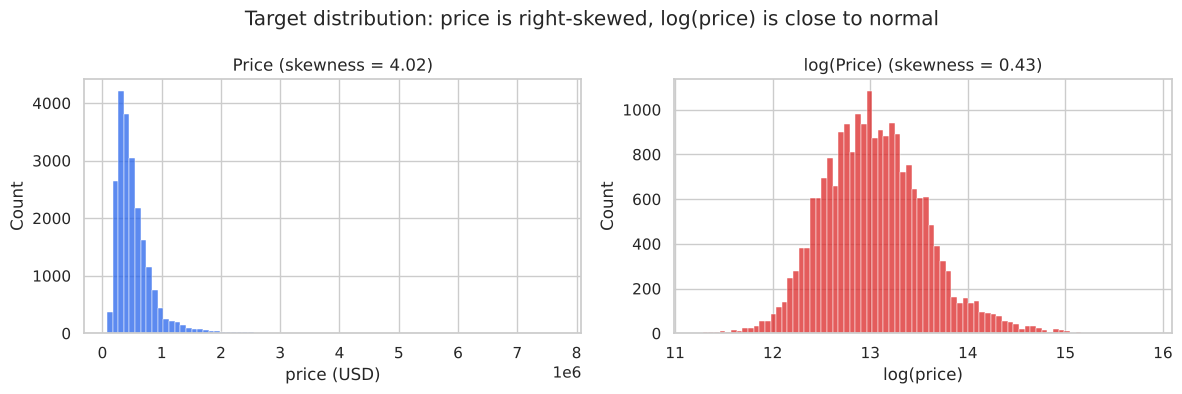

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=80, ax=axes[0], color=C_MAIN)
axes[0].set_title(f"Price (skewness = {df['price'].skew():.2f})")
axes[0].set_xlabel("price (USD)")
sns.histplot(np.log(df["price"]), bins=80, ax=axes[1], color=C_ACC)
axes[1].set_title(f"log(Price) (skewness = {np.log(df['price']).skew():.2f})")
axes[1].set_xlabel("log(price)")
plt.suptitle("Target distribution: price is right-skewed, log(price) is close to normal")
plt.tight_layout()
savefig("01_target_distribution.png")

sqft_living      0.702
grade            0.667
sqft_above       0.606
sqft_living15    0.585
bathrooms        0.525
view             0.397
sqft_basement    0.324
bedrooms         0.308
lat              0.307
waterfront       0.266
floors           0.257
yr_renovated     0.126
sqft_lot         0.090
sqft_lot15       0.082
yr_built         0.054
condition        0.036
long             0.022
zipcode         -0.053
Name: price, dtype: float64


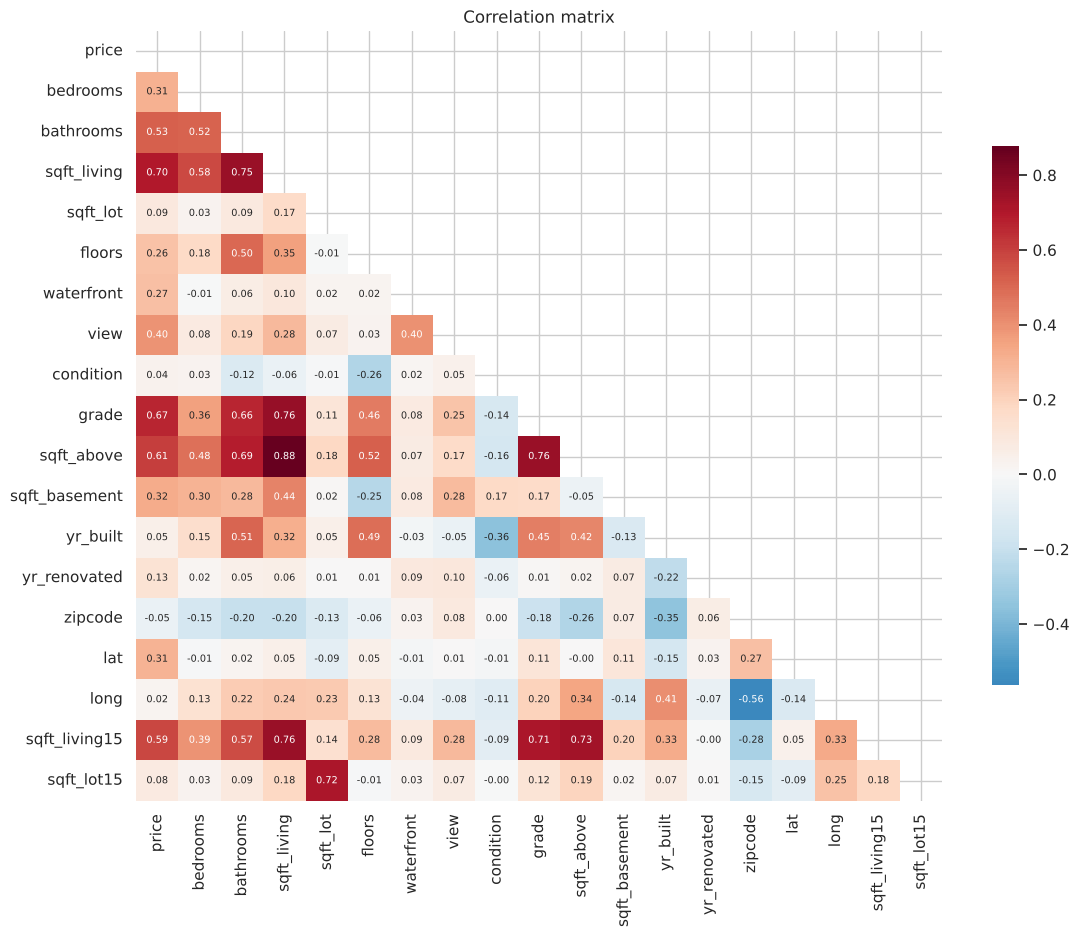

In [6]:
num_cols = df.drop(columns=["id", "date"]).columns
corr = df[num_cols].corr()
plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"shrink": .7})
plt.title("Correlation matrix")
savefig("02_correlation_heatmap.png")
print(corr["price"].drop("price").sort_values(ascending=False).round(3))

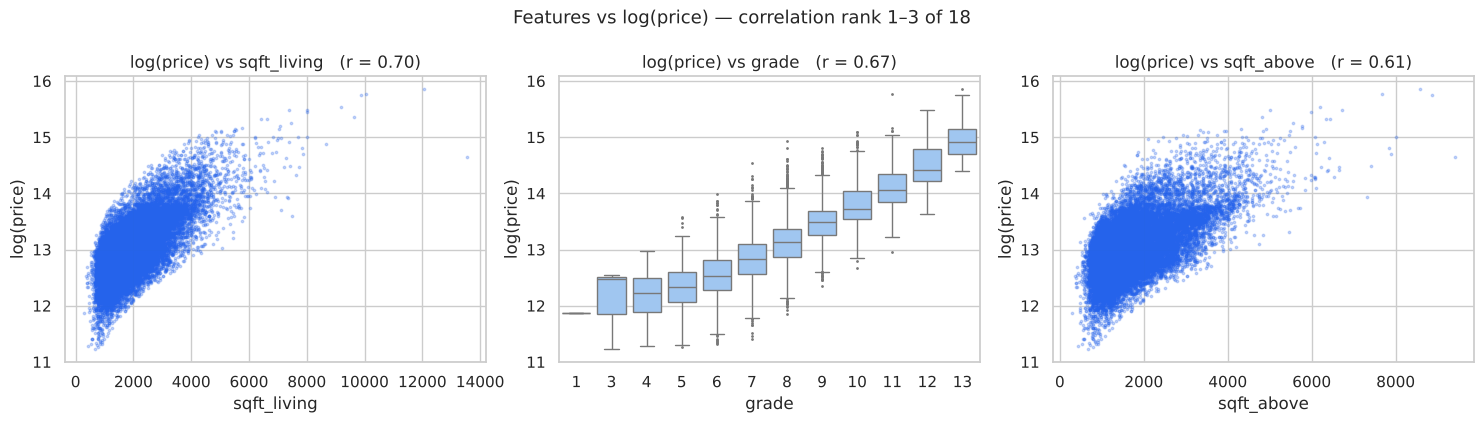

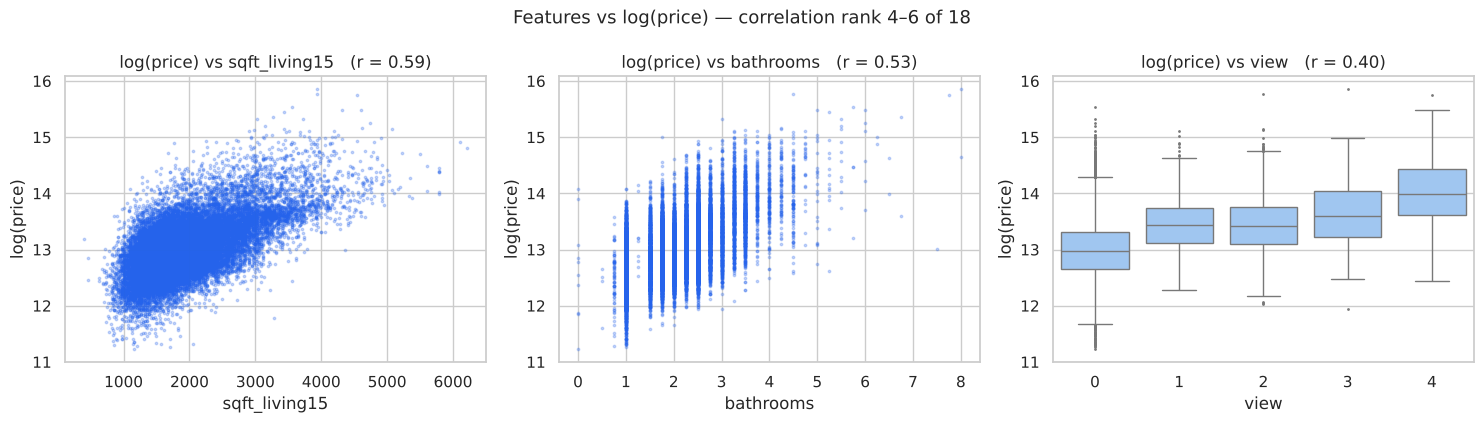

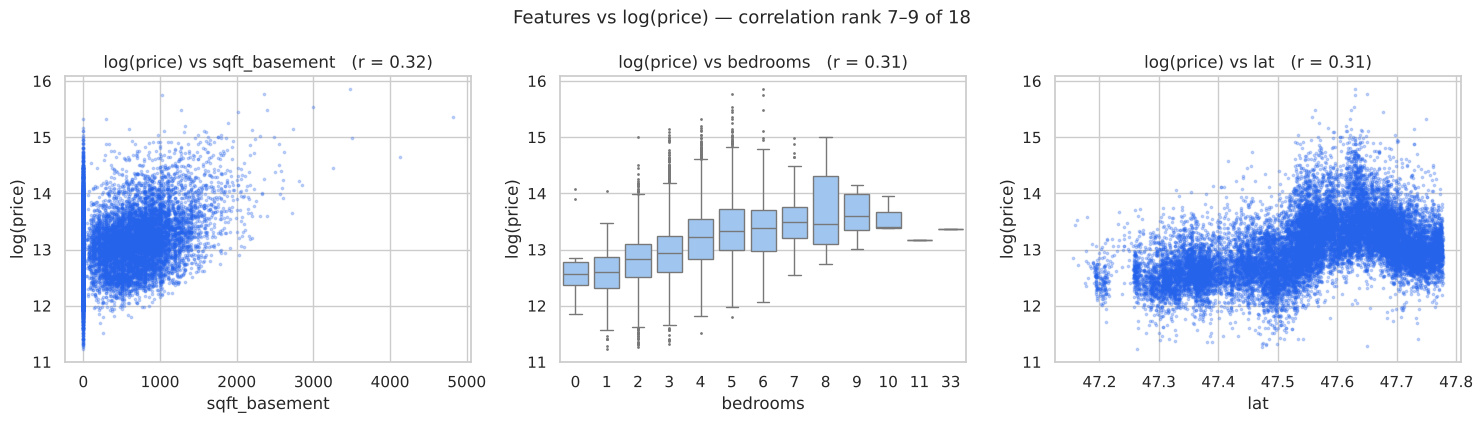

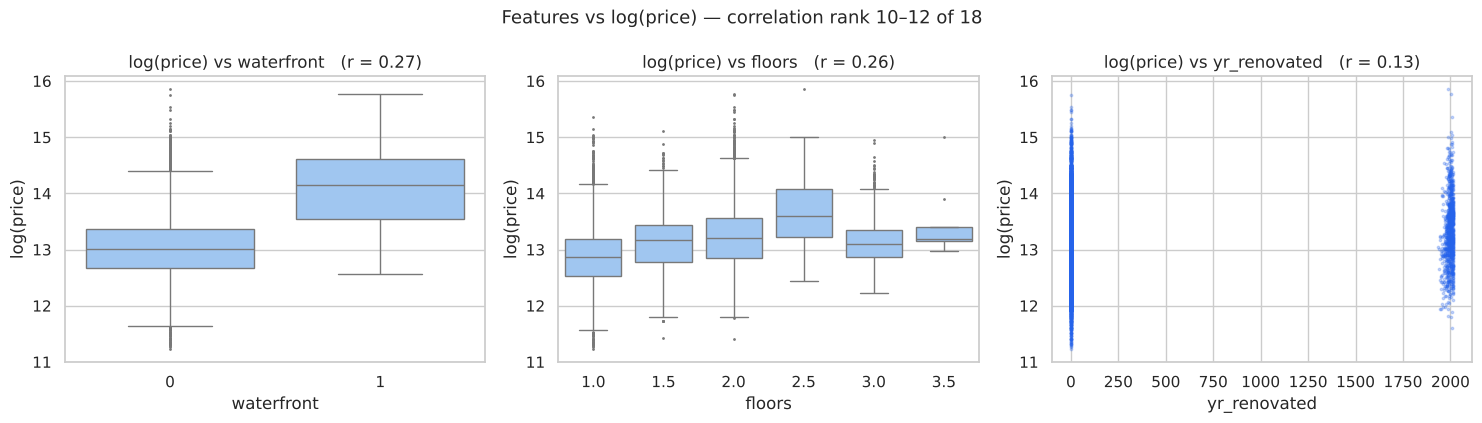

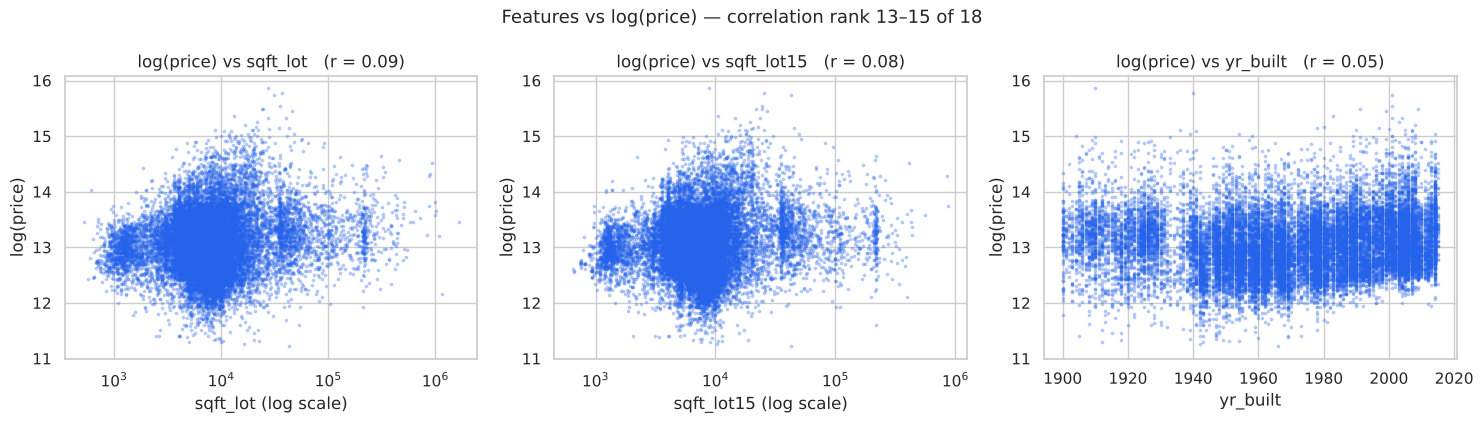

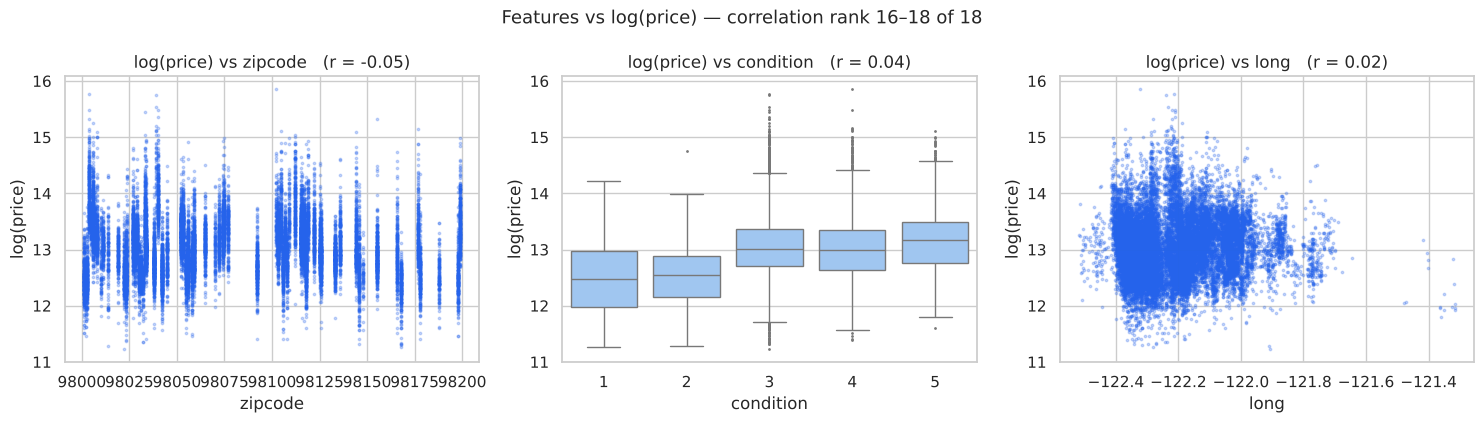

In [7]:
# 全部 18 個特徵 vs log(price)，依與 price 的相關係數由高到低排列
feat_cols = corr["price"].drop("price").abs().sort_values(ascending=False).index
log_price = np.log(df["price"])
for part in range(6):                       # 每 3 個特徵一張圖，共 6 張
    cols = feat_cols[part * 3:(part + 1) * 3]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
    for ax, col in zip(axes.ravel(), cols):
        r = df[col].corr(df["price"])
        if df[col].nunique() <= 15:
            sns.boxplot(x=df[col], y=log_price, ax=ax, color=C_BAND, fliersize=1)
        else:
            ax.scatter(df[col], log_price, s=3, alpha=.25, color=C_MAIN)
            if col in ["sqft_lot", "sqft_lot15"]:
                ax.set_xscale("log")
        ax.set_title(f"log(price) vs {col}   (r = {r:.2f})")
        ax.set_xlabel(col + (" (log scale)" if col in ["sqft_lot", "sqft_lot15"] else ""))
        ax.set_ylabel("log(price)")
    plt.suptitle(f"Features vs log(price) — correlation rank {part*3+1}–{part*3+3} of 18", fontsize=13)
    plt.tight_layout()
    savefig(f"03{'abcdef'[part]}_features_vs_price_{part+1}.png")

**Data Understanding 小結**
- 無缺失值；`id` 重複代表同一房屋多次成交，屬合理紀錄予以保留。
- `price` 明顯右偏，取 log 後接近常態，較符合線性回歸的誤差常態假設。
- 與價格最相關的是 `sqft_living`、`grade`、`sqft_above`、`sqft_living15`、`bathrooms`。
- `sqft_living = sqft_above + sqft_basement` 為完全線性相依，需處理多重共線性。
- `bedrooms` 有 33 房的極端值（面積只有約 1,600 sqft），應為輸入錯誤。

## 3. Data Preparation

In [8]:
d = df.copy()
d["date"] = pd.to_datetime(d["date"].astype(str).str[:8], format="%Y%m%d")
d["sale_year"] = d["date"].dt.year
d["sale_month"] = d["date"].dt.month
d["house_age"] = d["sale_year"] - d["yr_built"]
d["is_renovated"] = (d["yr_renovated"] > 0).astype(int)
d["has_basement"] = (d["sqft_basement"] > 0).astype(int)

n0 = len(d)
d = d[(d["bedrooms"] > 0) & (d["bedrooms"] <= 11) & (d["bathrooms"] > 0)]
print(f"移除異常值（0 房 / 0 衛浴 / 33 房）：{n0 - len(d)} 筆，剩 {len(d)} 筆")

for c in ["sqft_living", "sqft_lot", "sqft_living15", "sqft_lot15"]:
    d["log_" + c] = np.log(d[c])
d["log_price"] = np.log(d["price"])

FEATURES = ["bedrooms", "bathrooms", "log_sqft_living", "log_sqft_lot", "floors",
            "waterfront", "view", "condition", "grade", "has_basement", "house_age",
            "is_renovated", "lat", "long", "log_sqft_living15", "log_sqft_lot15",
            "sale_month", "sale_year"]
TARGET = "log_price"
print("候選特徵數：", len(FEATURES))

移除異常值（0 房 / 0 衛浴 / 33 房）：17 筆，剩 21596 筆
候選特徵數： 18


**處理說明**
| 處理 | 理由 |
|---|---|
| price → log(price) | 修正右偏，讓殘差更接近常態、變異數更穩定；係數可解讀為百分比變化 |
| 面積類欄位取 log | 面積與價格是「倍數」關係，log-log 下更線性 |
| 刪除 `sqft_above` | 與 sqft_living、sqft_basement 完全共線，改用 `has_basement` |
| `yr_built` → `house_age`、`yr_renovated` → `is_renovated` | yr_renovated 大多為 0，二元化較合理 |
| `date` → `sale_year`、`sale_month` | 捕捉時間趨勢與季節性 |
| 刪除 `zipcode` | 數值大小無意義（70 個類別），地點以 lat/long 表示 |

切分 80% 訓練 / 20% 測試；**所有特徵選擇只在訓練集上進行**，避免資料洩漏。

In [9]:
X = d[FEATURES].astype(float)
y = d[TARGET].values
price = d["price"].values
X_train, X_test, y_train, y_test, p_train, p_test = train_test_split(
    X, y, price, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (17276, 18)  Test: (4320, 18)


### 共線性檢查：VIF（Variance Inflation Factor）

In [10]:
def vif_table(Xdf):
    Xv = Xdf.values
    out = []
    for i, col in enumerate(Xdf.columns):
        others = np.delete(Xv, i, axis=1)
        r2 = LinearRegression().fit(others, Xv[:, i]).score(others, Xv[:, i])
        out.append((col, 1 / (1 - r2) if r2 < 1 else np.inf))
    return pd.DataFrame(out, columns=["feature", "VIF"]).sort_values("VIF", ascending=False)

vif_all = vif_table(X_train)
vif_all.round(2)

,feature,VIF
3,log_sqft_lot,6.88
15,log_sqft_lot15,6.58
2,log_sqft_living,5.95
1,bathrooms,3.34
8,grade,3.09
14,log_sqft_living15,2.86
17,sale_year,2.59
16,sale_month,2.58
10,house_age,2.36
4,floors,2.19


VIF > 10 代表嚴重共線性，5–10 為中度。

## 4. Modeling

### 4.1 自製 OLS 類別（計算標準誤、p-value、信賴區間、預測區間）

- 係數：$\hat\beta = (X^\top X)^{-1}X^\top y$，$\hat\sigma^2 = \dfrac{SSE}{n-p}$
- **平均反應的信賴區間 (CI)**：$\hat y_0 \pm t_{\alpha/2,\,n-p}\;\hat\sigma\sqrt{x_0^\top (X^\top X)^{-1} x_0}$
- **個別觀測的預測區間 (PI)**：$\hat y_0 \pm t_{\alpha/2,\,n-p}\;\hat\sigma\sqrt{1 + x_0^\top (X^\top X)^{-1} x_0}$

PI 多了「單筆觀測本身的誤差」，因此一定比 CI 寬。

In [11]:
class OLS:
    def fit(self, X, y):
        self.cols = list(X.columns) if hasattr(X, "columns") else None
        X1 = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
        y = np.asarray(y, float)
        self.n, self.p = X1.shape
        self.XtX_inv = np.linalg.pinv(X1.T @ X1)
        self.beta = self.XtX_inv @ X1.T @ y
        self.fitted = X1 @ self.beta
        self.resid = y - self.fitted
        self.df_resid = self.n - self.p
        sse = float(self.resid @ self.resid)
        self.sigma2 = sse / self.df_resid
        self.se = np.sqrt(np.diag(self.sigma2 * self.XtX_inv))
        self.t = self.beta / self.se
        self.pvalues = 2 * stats.t.sf(np.abs(self.t), self.df_resid)
        sst = float(((y - y.mean()) ** 2).sum())
        self.r2 = 1 - sse / sst
        self.adj_r2 = 1 - (1 - self.r2) * (self.n - 1) / self.df_resid
        k = self.p - 1                                    # 整體 F 檢定：H0 全部係數 = 0
        self.f_stat = (self.r2 / k) / ((1 - self.r2) / self.df_resid) if k > 0 else np.nan
        self.f_pvalue = stats.f.sf(self.f_stat, k, self.df_resid) if k > 0 else np.nan
        self.mae = float(np.mean(np.abs(self.resid)))
        ll = -self.n / 2 * (np.log(2 * np.pi * sse / self.n) + 1)
        self.aic = -2 * ll + 2 * self.p
        self.bic = -2 * ll + np.log(self.n) * self.p
        return self

    def summary(self, alpha=0.05):
        tc = stats.t.ppf(1 - alpha / 2, self.df_resid)
        names = ["const"] + (self.cols or [f"x{i}" for i in range(1, self.p)])
        return pd.DataFrame({"coef": self.beta, "std_err": self.se, "t": self.t,
                             "p_value": self.pvalues,
                             "ci_low": self.beta - tc * self.se,
                             "ci_high": self.beta + tc * self.se}, index=names)

    def predict(self, X, alpha=0.05, interval=None):
        X1 = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
        yhat = X1 @ self.beta
        if interval is None:
            return yhat
        h = np.einsum("ij,jk,ik->i", X1, self.XtX_inv, X1)   # x0' (X'X)^-1 x0
        tc = stats.t.ppf(1 - alpha / 2, self.df_resid)
        se = np.sqrt(self.sigma2 * (h + (1 if interval == "prediction" else 0)))
        return yhat, yhat - tc * se, yhat + tc * se

### 4.2 基底模型 (Baseline OLS)

以普通最小平方法 (OLS) 多元線性回歸、全部 18 個特徵作為基準，
建立特徵與 log(price) 之間的線性關係，並做整體 F 檢定。

In [12]:
ols_base = OLS().fit(X_train, y_train)
base_pred = ols_base.predict(X_test)
print(f"Baseline OLS（k = 18）：Train R² = {ols_base.r2:.4f}，Adj R² = {ols_base.adj_r2:.4f}，"
      f"Train MAE(log) = {ols_base.mae:.4f}")
print(f"  F = {ols_base.f_stat:,.1f}（df = 18, {ols_base.df_resid}），p-value = {ols_base.f_pvalue:.3g}")
print(f"  Test R² = {r2_score(y_test, base_pred):.4f}")

Baseline OLS（k = 18）：Train R² = 0.7754，Adj R² = 0.7752，Train MAE(log) = 0.1929
  F = 3,310.8（df = 18, 17257），p-value = 0
  Test R² = 0.7621


### 4.3 特徵選擇演算法 (Feature Selection Algorithms)

比較 5 種演算法，每一種都產生「k = 1…18 時要用哪 k 個特徵」的排序，全部只用訓練集：
1. **Lasso (L1)**：沿 Lasso 正則化路徑，依特徵係數「離開 0」的先後排序。
2. **Forward SFS**：從 0 個特徵開始，每次加入讓 5-fold CV R² 提升最多的特徵。
3. **RFE**：從全部特徵開始，反覆刪除標準化係數絕對值最小的特徵。
4. **ElasticNet (L1 + L2, l1_ratio = 0.5)**：同 Lasso，沿彈性網路路徑排序；共線性高時較穩定。
5. **Exhaustive Search**：窮舉全部 2¹⁸ − 1 = 262,143 種子集，找出每個 k 下訓練 SSE 最小的組合。

In [13]:
from itertools import combinations
from sklearn.linear_model import lasso_path, enet_path, ElasticNetCV

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scaler_fs = StandardScaler().fit(X_train)
Xs_train = scaler_fs.transform(X_train)
yc_train = y_train - y_train.mean()
p_feat = len(FEATURES)

def path_order(path_fn, l1_ratio=1.0):
    """依係數第一次變成非 0 的先後排序特徵（正則化路徑上的進入順序）"""
    a_max = np.max(np.abs(Xs_train.T @ yc_train)) / len(yc_train) / l1_ratio
    alphas = a_max * np.logspace(0, -5, 600)
    kw = {} if path_fn is lasso_path else {"l1_ratio": l1_ratio}
    _, coefs, _ = path_fn(Xs_train, yc_train, alphas=alphas, **kw)
    nz = np.abs(coefs) > 1e-10
    first = np.where(nz.any(axis=1), nz.argmax(axis=1), len(alphas))
    return [FEATURES[i] for i in np.argsort(first, kind="stable")]

# (1) Lasso 與 (4) ElasticNet：路徑進入順序 + CV 選出的最佳 alpha
order_lasso = path_order(lasso_path)
order_enet = path_order(enet_path, l1_ratio=0.5)
lasso_cv = LassoCV(cv=kf, random_state=RANDOM_STATE).fit(Xs_train, y_train)
enet_cv = ElasticNetCV(l1_ratio=0.5, cv=kf, random_state=RANDOM_STATE).fit(Xs_train, y_train)
print(f"LassoCV:      alpha = {lasso_cv.alpha_:.5f}，保留 {(np.abs(lasso_cv.coef_) > 1e-6).sum()} 個特徵")
print(f"ElasticNetCV: alpha = {enet_cv.alpha_:.5f}，保留 {(np.abs(enet_cv.coef_) > 1e-6).sum()} 個特徵")

# (2) Forward SFS（以 5-fold CV R² 為準則）
def cv_r2(cols):
    return cross_val_score(LinearRegression(), X_train[cols], y_train, cv=kf, scoring="r2").mean()

order_fwd, remaining = [], FEATURES.copy()
while remaining:
    scores = {f: cv_r2(order_fwd + [f]) for f in remaining}
    best = max(scores, key=scores.get)
    order_fwd.append(best)
    remaining.remove(best)

# (3) RFE：n_features_to_select=1 可得到完整的刪除順序（ranking 1 = 最後留下）
rfe_full = RFE(LinearRegression(), n_features_to_select=1).fit(Xs_train, y_train)
order_rfe = [FEATURES[i] for i in np.argsort(rfe_full.ranking_)]

# (5) Exhaustive Search：用中心化後的 Gram 矩陣快速計算每個子集的 SSE
Xc = X_train.values - X_train.values.mean(axis=0)
G, b, yy = Xc.T @ Xc, Xc.T @ yc_train, float(yc_train @ yc_train)
best_sets = {}
for k in range(1, p_feat + 1):
    best_sse, best_S = np.inf, None
    for S in combinations(range(p_feat), k):
        S = list(S)
        bs = b[S]
        sse = yy - bs @ np.linalg.solve(G[np.ix_(S, S)], bs)
        if sse < best_sse:
            best_sse, best_S = sse, S
    best_sets[k] = [FEATURES[i] for i in best_S]
print("Exhaustive search 完成：共評估", 2 ** p_feat - 1, "種子集")

subsets = {
    "Lasso":      {k: order_lasso[:k] for k in range(1, p_feat + 1)},
    "Forward SFS": {k: order_fwd[:k] for k in range(1, p_feat + 1)},
    "RFE":        {k: order_rfe[:k] for k in range(1, p_feat + 1)},
    "ElasticNet": {k: order_enet[:k] for k in range(1, p_feat + 1)},
    "Exhaustive": best_sets,
}

# 各方法的特徵排序（數字 = 第幾個被選入；Exhaustive 為該特徵最早出現在最佳子集的 k）
rank_tbl = pd.DataFrame(index=FEATURES)
for m, sub in subsets.items():
    rank_tbl[m] = [min(k for k, s in sub.items() if f in s) for f in FEATURES]
rank_tbl = rank_tbl.sort_values("Exhaustive")
rank_tbl.to_csv(os.path.join(OUT_DIR, "feature_rank_by_method.csv"))
rank_tbl

LassoCV:      alpha = 0.00037，保留 18 個特徵
ElasticNetCV: alpha = 0.00074，保留 18 個特徵
Exhaustive search 完成：共評估 262143 種子集


,Lasso,Forward SFS,RFE,ElasticNet,Exhaustive
grade,1,1,1,1,1
log_sqft_living,2,3,3,2,2
lat,3,2,2,3,2
house_age,6,4,4,6,4
view,5,5,7,5,5
log_sqft_living15,4,6,5,4,6
bathrooms,9,7,6,7,7
waterfront,7,8,8,8,8
condition,8,9,9,9,9
floors,11,10,10,11,10


### 4.4 特徵數量與模型評估 (Model Selection by k)

對每個方法、每個 k，以選出的 k 個特徵重新配適 OLS，並記錄
5-fold CV RMSE（訓練集內）、Test RMSE（美元）、Test R²、Adjusted R²、MAE 與 BIC。

In [14]:
def to_price(log_pred, resid):
    """log → 價格，使用 Duan smearing 修正 exp(E[log y]) 低估平均值的偏誤"""
    return np.exp(log_pred) * np.mean(np.exp(resid))

rows = []
for m, sub in subsets.items():
    for k, cols in sub.items():
        mdl = OLS().fit(X_train[cols], y_train)
        pte = mdl.predict(X_test[cols])
        pp = to_price(pte, mdl.resid)
        cv_rmse = -cross_val_score(LinearRegression(), X_train[cols], y_train, cv=kf,
                                   scoring="neg_root_mean_squared_error").mean()
        r2t = r2_score(y_test, pte)
        rows.append({"method": m, "k": k, "features": ", ".join(cols),
                     "CV_RMSE_log": cv_rmse, "Test_RMSE_USD": np.sqrt(mean_squared_error(p_test, pp)),
                     "Test_MAE_USD": mean_absolute_error(p_test, pp), "Test_R2": r2t,
                     "Test_adj_R2": 1 - (1 - r2t) * (len(y_test) - 1) / (len(y_test) - k - 1),
                     "BIC": mdl.bic})
kres = pd.DataFrame(rows)
kres.to_csv(os.path.join(OUT_DIR, "k_comparison_all_methods.csv"), index=False)

# 與該網站相同：列出 k = 1–5 的 Test RMSE
pd.pivot_table(kres[kres.k <= 5], index="k", columns="method", values="Test_RMSE_USD").round(0)

method,ElasticNet,Exhaustive,Forward SFS,Lasso,RFE
k,,,,,
1,255587.0,255587.0,255587.0,255587.0,255587.0
2,240413.0,246518.0,241035.0,240413.0,241035.0
3,222713.0,222713.0,222713.0,222713.0,222713.0
4,224959.0,205964.0,205964.0,224959.0,205964.0
5,207188.0,193667.0,193667.0,207188.0,208078.0


In [15]:
# 甜點區 (Sweet Spot)：用訓練集 CV RMSE 選 k（不偷看測試集），並採「1 個標準誤」簡約原則
K_BEST_BY = {}
for m in subsets:
    sub = kres[kres.method == m].set_index("k")
    k_min = int(sub["CV_RMSE_log"].idxmin())
    K_BEST_BY[m] = k_min
sweet = pd.DataFrame([{
    "method": m, "CV 最佳 k": K_BEST_BY[m],
    "Test RMSE @ 最佳 k": kres[(kres.method == m) & (kres.k == K_BEST_BY[m])]["Test_RMSE_USD"].iloc[0],
    "Test RMSE 最小的 k": int(kres[kres.method == m].set_index("k")["Test_RMSE_USD"].idxmin()),
    "Test RMSE @ k=18": kres[(kres.method == m) & (kres.k == 18)]["Test_RMSE_USD"].iloc[0],
} for m in subsets]).set_index("method")

# 簡約選擇：Exhaustive 曲線上，CV RMSE 落在最小值 + 0.002 以內的最小 k
ex = kres[kres.method == "Exhaustive"].set_index("k")
K_BEST = int(ex[ex["CV_RMSE_log"] <= ex["CV_RMSE_log"].min() + 0.002].index.min())
SELECTED = subsets["Exhaustive"][K_BEST]
print(f"簡約選擇 k = {K_BEST}：", SELECTED)
print("被排除的特徵：", [f for f in FEATURES if f not in SELECTED])
for m in subsets:
    same = set(subsets[m][K_BEST]) == set(SELECTED)
    print(f"  {m:12s} 在 k = {K_BEST} 選出的特徵與 Exhaustive {'完全相同' if same else '不同'}")
sweet.round(0)

簡約選擇 k = 11： ['bathrooms', 'log_sqft_living', 'floors', 'waterfront', 'view', 'condition', 'grade', 'house_age', 'lat', 'log_sqft_living15', 'sale_year']
被排除的特徵： ['bedrooms', 'log_sqft_lot', 'has_basement', 'is_renovated', 'long', 'log_sqft_lot15', 'sale_month']
  Lasso        在 k = 11 選出的特徵與 Exhaustive 不同
  Forward SFS  在 k = 11 選出的特徵與 Exhaustive 完全相同
  RFE          在 k = 11 選出的特徵與 Exhaustive 不同
  ElasticNet   在 k = 11 選出的特徵與 Exhaustive 不同
  Exhaustive   在 k = 11 選出的特徵與 Exhaustive 完全相同


,CV 最佳 k,Test RMSE @ 最佳 k,Test RMSE 最小的 k,Test RMSE @ k=18
method,,,,
Lasso,17,177800.0,15,177852.0
Forward SFS,17,177800.0,14,177852.0
RFE,17,177800.0,15,177852.0
ElasticNet,17,177800.0,15,177852.0
Exhaustive,17,177800.0,14,177852.0


k ≥ 簡約 k 之後 Test RMSE 的變動幅度（美元）：
method
ElasticNet     1524.0
Exhaustive     2160.0
Forward SFS    2160.0
Lasso          1524.0
RFE            1823.0
dtype: float64


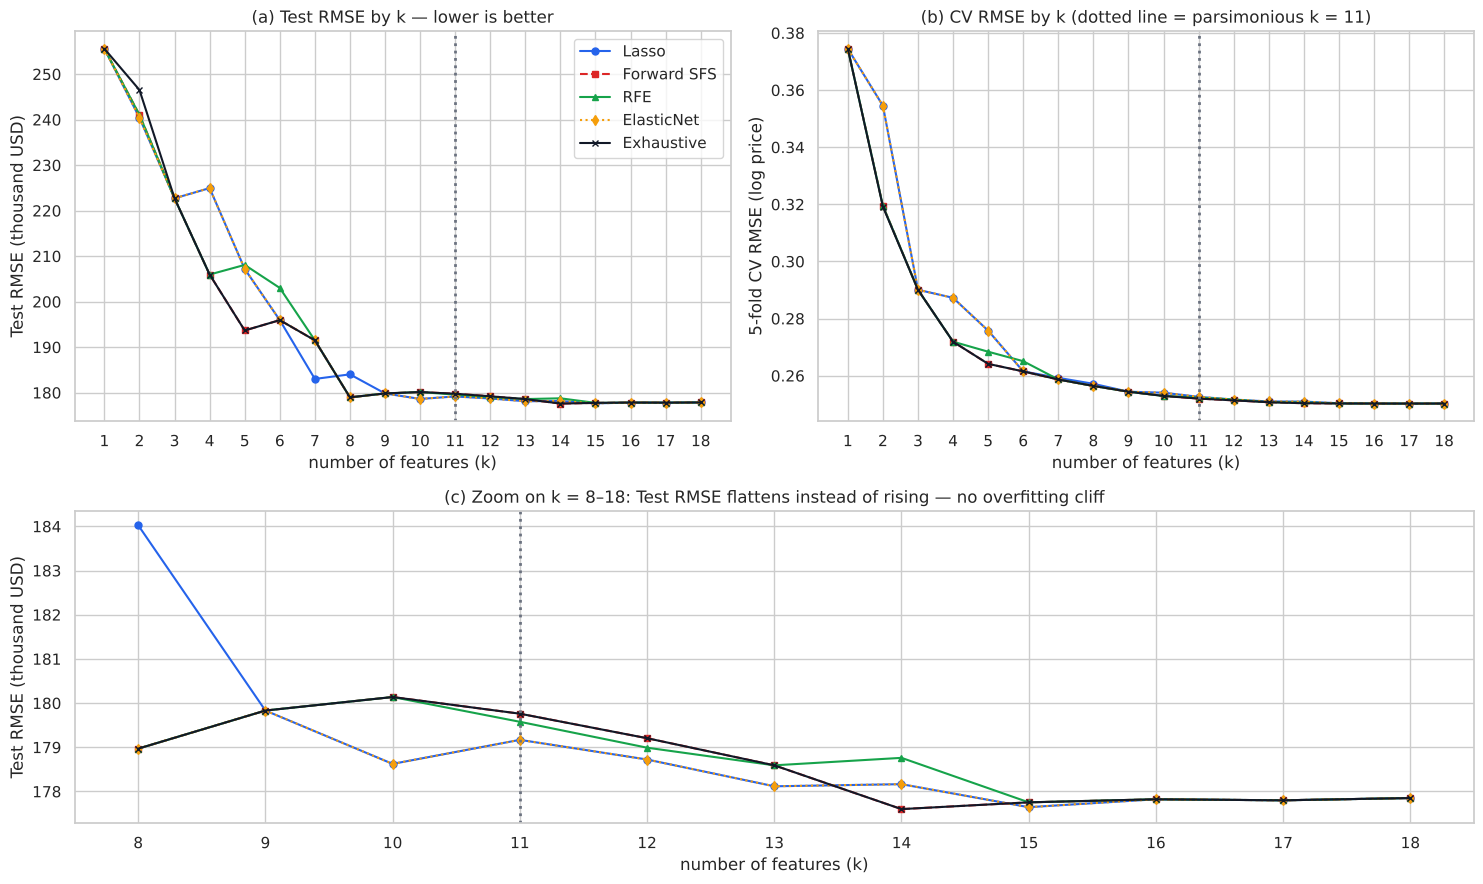

In [16]:
mcolors = {"Lasso": "#2563EB", "Forward SFS": "#DC2626", "RFE": "#16A34A",
           "ElasticNet": "#F59E0B", "Exhaustive": "#111827"}
mstyle = {"Lasso": "o-", "Forward SFS": "s--", "RFE": "^-", "ElasticNet": "d:", "Exhaustive": "x-"}
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(15, 9))
gs = GridSpec(2, 2, height_ratios=[1.25, 1], figure=fig)
ax_a, ax_b, ax_c = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
for m in subsets:
    s = kres[kres.method == m]
    ax_a.plot(s.k, s.Test_RMSE_USD / 1000, mstyle[m], color=mcolors[m], ms=5, label=m)
    ax_b.plot(s.k, s.CV_RMSE_log, mstyle[m], color=mcolors[m], ms=5, label=m)
    z = s[s.k >= 8]
    ax_c.plot(z.k, z.Test_RMSE_USD / 1000, mstyle[m], color=mcolors[m], ms=5, label=m)
for ax in (ax_a, ax_b):
    ax.set_xticks(range(1, p_feat + 1))
for ax in (ax_a, ax_b, ax_c):
    ax.axvline(K_BEST, color=C_GREY, ls=":", lw=2)
    ax.set_xlabel("number of features (k)")
ax_c.set_xticks(range(8, p_feat + 1))
ax_a.set_ylabel("Test RMSE (thousand USD)")
ax_a.set_title("(a) Test RMSE by k — lower is better")
ax_b.set_ylabel("5-fold CV RMSE (log price)")
ax_b.set_title(f"(b) CV RMSE by k (dotted line = parsimonious k = {K_BEST})")
ax_c.set_ylabel("Test RMSE (thousand USD)")
ax_c.set_title("(c) Zoom on k = 8–18: Test RMSE flattens instead of rising — no overfitting cliff")
ax_a.legend()
plt.tight_layout()
savefig("04_fs_k_comparison.png")
tail = kres[kres.k >= K_BEST].groupby("method")["Test_RMSE_USD"].agg(["min", "max"])
print("k ≥ 簡約 k 之後 Test RMSE 的變動幅度（美元）：")
print((tail["max"] - tail["min"]).round(0))

In [17]:
vif_sel = vif_table(X_train[SELECTED])
vif_sel.round(2)

,feature,VIF
1,log_sqft_living,4.14
0,bathrooms,3.08
6,grade,2.94
9,log_sqft_living15,2.59
7,house_age,1.85
2,floors,1.58
4,view,1.36
3,waterfront,1.20
5,condition,1.19
8,lat,1.09


### 4.5 不同特徵選擇方法建出的模型

每種方法都用**同一個簡約規則**選 k：在該方法的曲線上，取 CV RMSE 與其最小值差距 < 0.002 的最小 k。
再用選出的特徵配適 OLS，與「單純線性回歸」及「Baseline OLS（18 個特徵）」一起比較。
主模型取「特徵數最少」者（各方法 CV RMSE 差距 < 0.001，精簡度是主要差異）。

In [18]:
def to_price(log_pred, resid):
    """log → 價格，使用 Duan smearing 修正 exp(E[log y]) 低估平均值的偏誤"""
    return np.exp(log_pred) * np.mean(np.exp(resid))

K_BY_METHOD = {}
for m in subsets:
    s = kres[kres.method == m].set_index("k")["CV_RMSE_log"]
    K_BY_METHOD[m] = int(s[s <= s.min() + 0.002].index.min())

model_sets = {"Simple LR": ["log_sqft_living"], "Baseline OLS": FEATURES}
for m in subsets:
    model_sets[f"OLS + {m}"] = subsets[m][K_BY_METHOD[m]]

def evaluate(name, cols):
    mdl = OLS().fit(X_train[cols], y_train)
    pte, lo, hi = mdl.predict(X_test[cols], interval="prediction")
    pp = to_price(pte, mdl.resid)
    r2 = r2_score(y_test, pte)
    n, k = len(y_test), len(cols)
    cv_rmse = -cross_val_score(LinearRegression(), X_train[cols], y_train, cv=kf,
                               scoring="neg_root_mean_squared_error").mean()
    return {"model": name, "k": k, "train_R2": mdl.r2, "train_adj_R2": mdl.adj_r2,
            "F_stat": mdl.f_stat, "CV_RMSE_log": cv_rmse,
            "test_R2": r2, "test_adj_R2": 1 - (1 - r2) * (n - 1) / (n - k - 1),
            "RMSE_USD": np.sqrt(mean_squared_error(p_test, pp)),
            "MAE_USD": mean_absolute_error(p_test, pp),
            "MAPE_%": np.mean(np.abs(p_test - pp) / p_test) * 100,
            "PI95_cover": np.mean((y_test >= lo) & (y_test <= hi)),
            "max_VIF": vif_table(X_train[cols])["VIF"].max() if k > 1 else np.nan}

results = pd.DataFrame([evaluate(n, c) for n, c in model_sets.items()]).set_index("model")
fs_rows = results.loc[[f"OLS + {m}" for m in subsets]]
MAIN = fs_rows.sort_values(["k", "CV_RMSE_log"]).index[0]
SELECTED = model_sets[MAIN]
K_BEST = len(SELECTED)
print("各方法選出的 k：", K_BY_METHOD)
print(f"主模型：{MAIN}（k = {K_BEST}）")
for m in subsets:
    if f"OLS + {m}" != MAIN and set(model_sets[f"OLS + {m}"]) == set(SELECTED):
        print(f"  {m} 選出的特徵與主模型完全相同")
results.to_csv(os.path.join(OUT_DIR, "model_comparison.csv"))
results.round(4)

各方法選出的 k： {'Lasso': 12, 'Forward SFS': 11, 'RFE': 12, 'ElasticNet': 12, 'Exhaustive': 11}
主模型：OLS + Forward SFS（k = 11）
  Exhaustive 選出的特徵與主模型完全相同


,k,train_R2,train_adj_R2,F_stat,CV_RMSE_log,test_R2,test_adj_R2,RMSE_USD,MAE_USD,MAPE_%,PI95_cover,max_VIF
model,,,,,,,,,,,,
Simple LR,1,0.4564,0.4564,14502.1870,0.3889,0.4511,0.4510,267443.7279,167798.1373,35.7153,0.9562,NaN
Baseline OLS,18,0.7754,0.7752,3310.7699,0.2502,0.7621,0.7611,177851.7064,109296.8941,20.9220,0.9403,6.8759
OLS + Lasso,12,0.7728,0.7726,4892.2272,0.2516,0.7600,0.7594,178723.6457,110446.0449,21.1371,0.9428,4.1427
OLS + Forward SFS,11,0.7721,0.7720,5317.3191,0.2520,0.7595,0.7589,179760.6269,110625.9214,21.1601,0.9435,4.1423
OLS + RFE,12,0.7727,0.7726,4891.3372,0.2516,0.7593,0.7586,178991.0437,109769.4733,21.0148,0.9414,5.2631
OLS + ElasticNet,12,0.7728,0.7726,4892.2272,0.2516,0.7600,0.7594,178723.6457,110446.0449,21.1371,0.9428,4.1427
OLS + Exhaustive,11,0.7721,0.7720,5317.3191,0.2520,0.7595,0.7589,179760.6270,110625.9215,21.1601,0.9435,4.1423


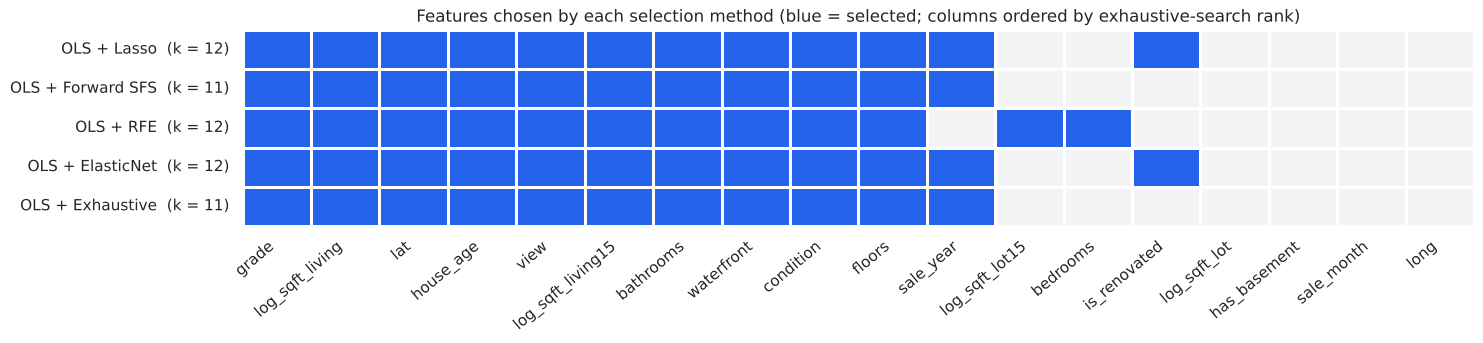

In [19]:
# 圖 6a：各方法選了哪些特徵（深色 = 選入）
sel_mat = pd.DataFrame(0, index=[f"OLS + {m}" for m in subsets], columns=rank_tbl.index)
for m in subsets:
    sel_mat.loc[f"OLS + {m}", model_sets[f"OLS + {m}"]] = 1
fig, ax = plt.subplots(figsize=(15, 3.6))
sns.heatmap(sel_mat, cmap=["#F3F4F6", C_MAIN], cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.set_yticklabels([f"{i}  (k = {sel_mat.loc[i].sum()})" for i in sel_mat.index], rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
ax.set_title("Features chosen by each selection method (blue = selected; columns ordered by exhaustive-search rank)")
plt.tight_layout()
savefig("06a_selected_features_by_method.png")

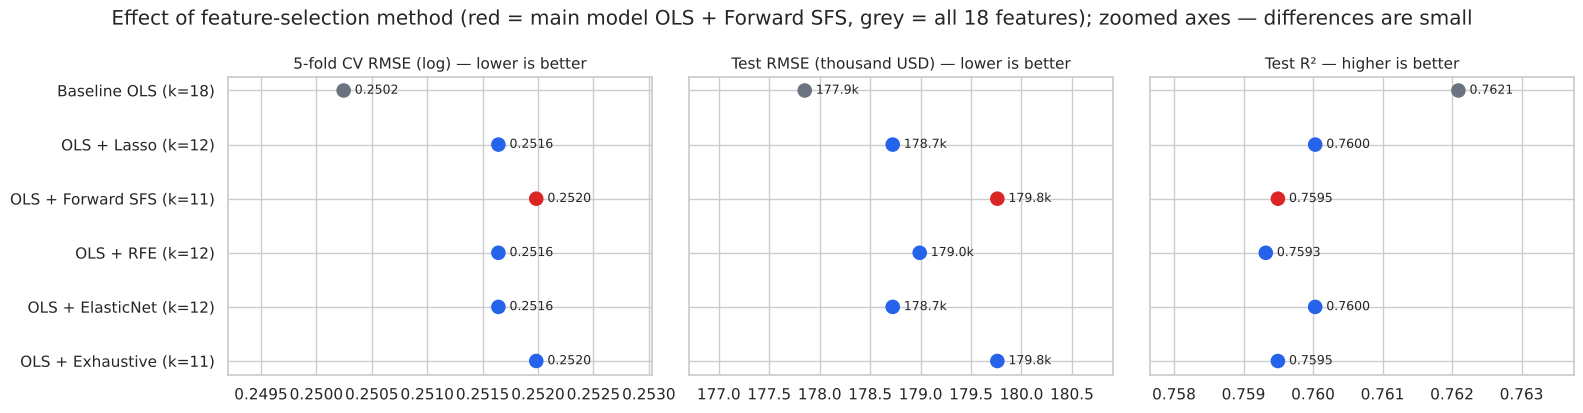

In [20]:
# 圖 6b：各方法模型在測試集的表現（不含單純線性回歸，以放大差異）
r = results.drop(index="Simple LR")
colors = [C_ACC if n == MAIN else (C_GREY if n == "Baseline OLS" else C_MAIN) for n in r.index]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
specs = [("CV_RMSE_log", "5-fold CV RMSE (log) — lower is better", "{:.4f}", 1),
         ("RMSE_USD", "Test RMSE (thousand USD) — lower is better", "{:.1f}k", 1000),
         ("test_R2", "Test R² — higher is better", "{:.4f}", 1)]
for ax, (col, title, fmt, div) in zip(axes, specs):
    vals = r[col] / div
    ypos = np.arange(len(vals))
    ax.scatter(vals, ypos, s=90, color=colors, zorder=3)
    ax.set_yticks(ypos)
    ax.set_yticklabels(r.index)
    lo_, hi_ = vals.min(), vals.max()
    pad = (hi_ - lo_) * 0.6 + 1e-9
    ax.set_xlim(lo_ - pad, hi_ + pad)
    for i, v in enumerate(vals):
        ax.annotate(fmt.format(v), (v, i), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
axes[0].set_yticklabels([f"{n} (k={int(r.loc[n, 'k'])})" for n in r.index])
plt.suptitle(f"Effect of feature-selection method (red = main model {MAIN}, grey = all 18 features); zoomed axes — differences are small")
plt.tight_layout()
savefig("06b_fs_method_comparison.png")

### 4.6 主模型的 OLS 統計摘要

In [21]:
ols = OLS().fit(X_train[SELECTED], y_train)
coef_tbl = ols.summary()
print(f"n = {ols.n}, k = {ols.p - 1}, R² = {ols.r2:.4f}, Adj R² = {ols.adj_r2:.4f}, "
      f"AIC = {ols.aic:.1f}, BIC = {ols.bic:.1f}")
print(f"整體 F 檢定：F = {ols.f_stat:,.1f}（df = {ols.p - 1}, {ols.df_resid}），p-value = {ols.f_pvalue:.3g}")
coef_tbl.to_csv(os.path.join(OUT_DIR, "ols_coefficients.csv"))
coef_tbl.round(5)

n = 17276, k = 11, R² = 0.7721, Adj R² = 0.7720, AIC = 1395.8, BIC = 1488.9
整體 F 檢定：F = 5,317.3（df = 11, 17264），p-value = 0


,coef,std_err,t,p_value,ci_low,ci_high
const,-150.60001,8.31887,-18.10342,0.0,-166.90584,-134.29418
grade,0.17426,0.00281,62.01129,0.0,0.16875,0.17977
lat,1.34572,0.01446,93.08786,0.0,1.31738,1.37405
log_sqft_living,0.27657,0.00920,30.07131,0.0,0.25854,0.29460
house_age,0.00387,0.00009,43.66003,0.0,0.00370,0.00404
view,0.06173,0.00291,21.24679,0.0,0.05603,0.06742
log_sqft_living15,0.21884,0.00942,23.22066,0.0,0.20037,0.23731
bathrooms,0.06947,0.00438,15.84333,0.0,0.06087,0.07806
waterfront,0.42466,0.02403,17.67178,0.0,0.37756,0.47177
condition,0.06153,0.00321,19.17258,0.0,0.05524,0.06782


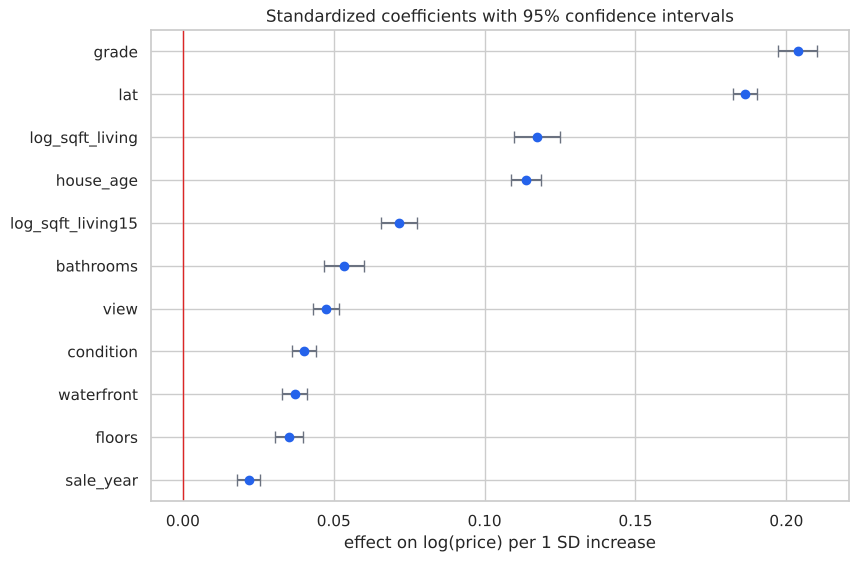

In [22]:
# 標準化係數 + 95% CI：比較各特徵影響力大小
ols_std = OLS().fit(pd.DataFrame(scaler_fs.transform(X_train)[:, [FEATURES.index(f) for f in SELECTED]],
                                 columns=SELECTED), y_train)
cs = ols_std.summary().drop("const").sort_values("coef")
plt.figure(figsize=(9, 0.42 * len(cs) + 1.5))
plt.errorbar(cs["coef"], cs.index, xerr=[cs["coef"] - cs["ci_low"], cs["ci_high"] - cs["coef"]],
             fmt="o", color=C_MAIN, ecolor=C_GREY, capsize=4)
plt.axvline(0, color=C_ACC, lw=1)
plt.title("Standardized coefficients with 95% confidence intervals")
plt.xlabel("effect on log(price) per 1 SD increase")
savefig("07_coefficients_ci.png")

**係數解讀（log-log / log-level）**
- `log_sqft_living` 係數 β：居住面積增加 1%，房價約增加 β%。
- `grade`、`view`、`waterfront`、`condition` 係數 β：每增加 1 單位，房價約增加 (e^β − 1) × 100%。
- `lat` 為正且影響大：越往北（靠近西雅圖市區）房價越高。

## 5. Evaluation

### 5.1 預測圖（含 95% 信賴區間與預測區間）

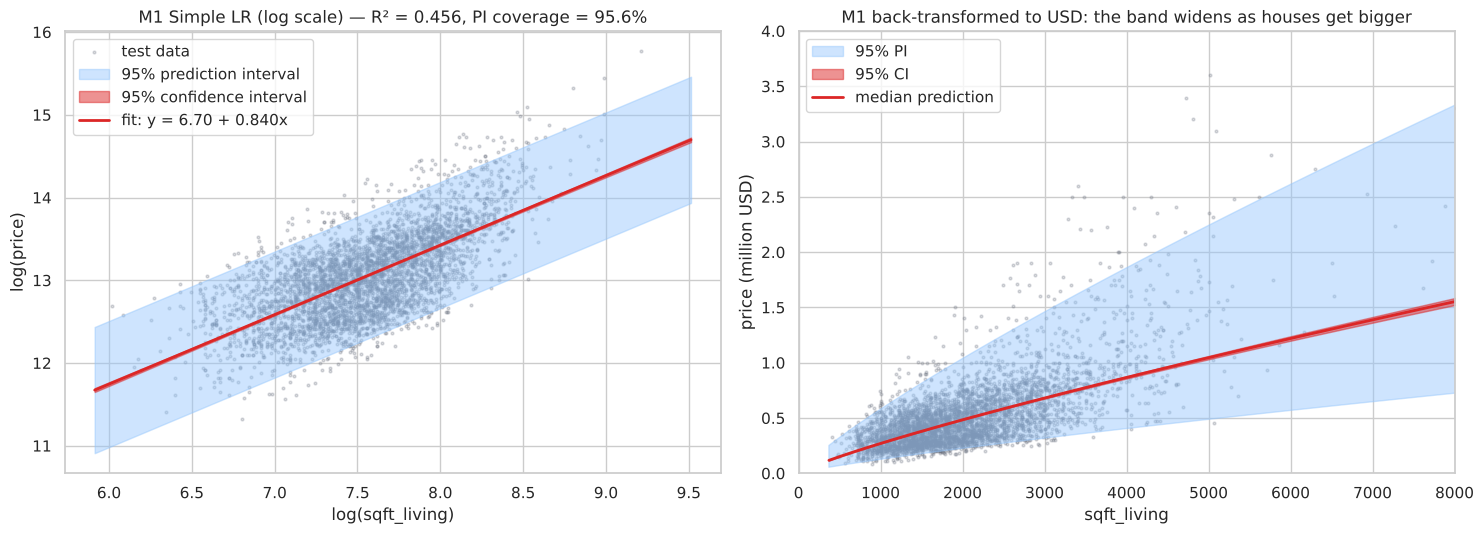

In [23]:
# (a) 單純線性回歸：log_sqft_living → log_price，畫出 CI 與 PI 帶
ols1 = OLS().fit(X_train[["log_sqft_living"]], y_train)
grid = np.linspace(X["log_sqft_living"].min(), X["log_sqft_living"].max(), 200)
gdf = pd.DataFrame({"log_sqft_living": grid})
yh, ci_lo, ci_hi = ols1.predict(gdf, interval="confidence")
_, pi_lo, pi_hi = ols1.predict(gdf, interval="prediction")
cov1 = np.mean((y_test >= ols1.predict(X_test[["log_sqft_living"]], interval="prediction")[1]) &
               (y_test <= ols1.predict(X_test[["log_sqft_living"]], interval="prediction")[2]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.scatter(X_test["log_sqft_living"], y_test, s=4, alpha=.25, color=C_GREY, label="test data")
ax.fill_between(grid, pi_lo, pi_hi, color=C_BAND, alpha=.45, label="95% prediction interval")
ax.fill_between(grid, ci_lo, ci_hi, color=C_ACC, alpha=.5, label="95% confidence interval")
ax.plot(grid, yh, color=C_ACC, lw=2, label=f"fit: y = {ols1.beta[0]:.2f} + {ols1.beta[1]:.3f}x")
ax.set_xlabel("log(sqft_living)")
ax.set_ylabel("log(price)")
ax.set_title(f"M1 Simple LR (log scale) — R² = {ols1.r2:.3f}, PI coverage = {cov1:.1%}")
ax.legend(loc="upper left")

ax = axes[1]
sq = np.exp(grid)
ax.scatter(X_test["log_sqft_living"].pipe(np.exp), p_test / 1e6, s=4, alpha=.25, color=C_GREY)
ax.fill_between(sq, np.exp(pi_lo) / 1e6, np.exp(pi_hi) / 1e6, color=C_BAND, alpha=.45, label="95% PI")
ax.fill_between(sq, np.exp(ci_lo) / 1e6, np.exp(ci_hi) / 1e6, color=C_ACC, alpha=.5, label="95% CI")
ax.plot(sq, np.exp(yh) / 1e6, color=C_ACC, lw=2, label="median prediction")
ax.set_xlim(0, 8000)
ax.set_ylim(0, 4)
ax.set_xlabel("sqft_living")
ax.set_ylabel("price (million USD)")
ax.set_title("M1 back-transformed to USD: the band widens as houses get bigger")
ax.legend(loc="upper left")
plt.tight_layout()
savefig("08_simple_lr_ci_pi.png")

主模型測試集 95% 預測區間涵蓋率：94.35%
平均 95% PI 寬度（log）：0.988 → 約為預測價格的 ×0.61 ~ ×1.64


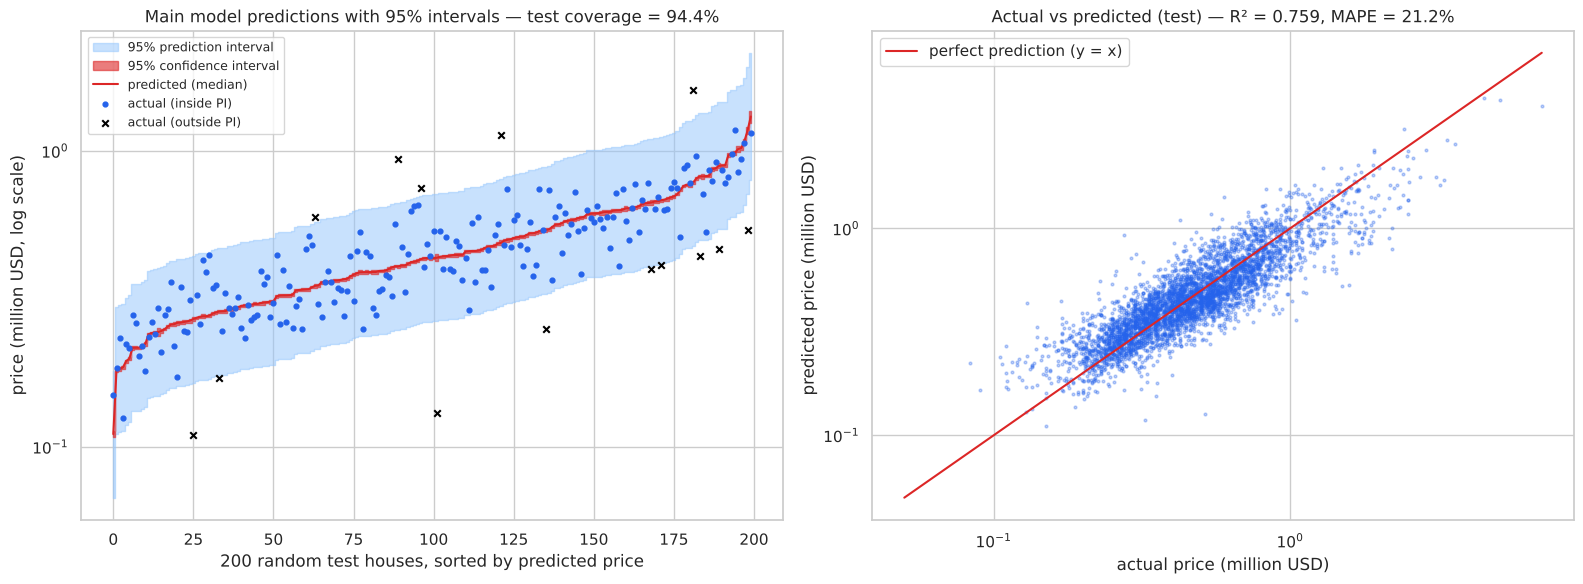

In [24]:
# (b) 主模型：測試集預測值與 95% 預測區間
yhat_te, pi_lo_te, pi_hi_te = ols.predict(X_test[SELECTED], interval="prediction")
_, ci_lo_te, ci_hi_te = ols.predict(X_test[SELECTED], interval="confidence")
inside = (y_test >= pi_lo_te) & (y_test <= pi_hi_te)
coverage = inside.mean()
print(f"主模型測試集 95% 預測區間涵蓋率：{coverage:.2%}")
print(f"平均 95% PI 寬度（log）：{np.mean(pi_hi_te - pi_lo_te):.3f}"
      f" → 約為預測價格的 ×{np.exp(-np.mean(pi_hi_te - pi_lo_te)/2):.2f} ~ ×{np.exp(np.mean(pi_hi_te - pi_lo_te)/2):.2f}")

rng = np.random.default_rng(RANDOM_STATE)
idx = np.sort(rng.choice(len(y_test), 200, replace=False))
order = idx[np.argsort(yhat_te[idx])]
xs = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax = axes[0]
ax.fill_between(xs, np.exp(pi_lo_te[order]) / 1e6, np.exp(pi_hi_te[order]) / 1e6,
                color=C_BAND, alpha=.5, step="mid", label="95% prediction interval")
ax.fill_between(xs, np.exp(ci_lo_te[order]) / 1e6, np.exp(ci_hi_te[order]) / 1e6,
                color=C_ACC, alpha=.6, step="mid", label="95% confidence interval")
ax.plot(xs, np.exp(yhat_te[order]) / 1e6, color=C_ACC, lw=1.5, label="predicted (median)")
ax.scatter(xs[inside[order]], p_test[order][inside[order]] / 1e6, s=12, color=C_MAIN, zorder=3,
           label="actual (inside PI)")
ax.scatter(xs[~inside[order]], p_test[order][~inside[order]] / 1e6, s=22, color="black",
           marker="x", zorder=3, label="actual (outside PI)")
ax.set_yscale("log")
ax.set_xlabel("200 random test houses, sorted by predicted price")
ax.set_ylabel("price (million USD, log scale)")
ax.set_title(f"Main model predictions with 95% intervals — test coverage = {coverage:.1%}")
ax.legend(loc="upper left", fontsize=9)

ax = axes[1]
price_hat = np.exp(yhat_te)
ax.scatter(p_test / 1e6, price_hat / 1e6, s=4, alpha=.3, color=C_MAIN)
lim = [0.05, max(p_test.max(), price_hat.max()) / 1e6]
ax.plot(lim, lim, color=C_ACC, lw=1.5, label="perfect prediction (y = x)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("actual price (million USD)")
ax.set_ylabel("predicted price (million USD)")
m3 = results.loc[MAIN]
ax.set_title(f"Actual vs predicted (test) — R² = {m3['test_R2']:.3f}, MAPE = {m3['MAPE_%']:.1f}%")
ax.legend()
plt.tight_layout()
savefig("09_main_model_prediction_intervals.png")

### 5.2 殘差診斷（線性回歸假設檢查）

| 假設 | 檢查方式 |
|---|---|
| 線性 | Residuals vs Fitted 無明顯曲線 |
| 誤差常態 | Q-Q plot、殘差直方圖 |
| 變異數同質 | Scale-Location 圖大致水平 |
| 誤差獨立 | Durbin-Watson ≈ 2 |
| 無嚴重共線性 | VIF < 10（見 4.2） |

Durbin-Watson = 2.019   Jarque-Bera = 543.7 (p = 8.46e-119)
殘差偏態 = 0.114，峰度 = 0.839


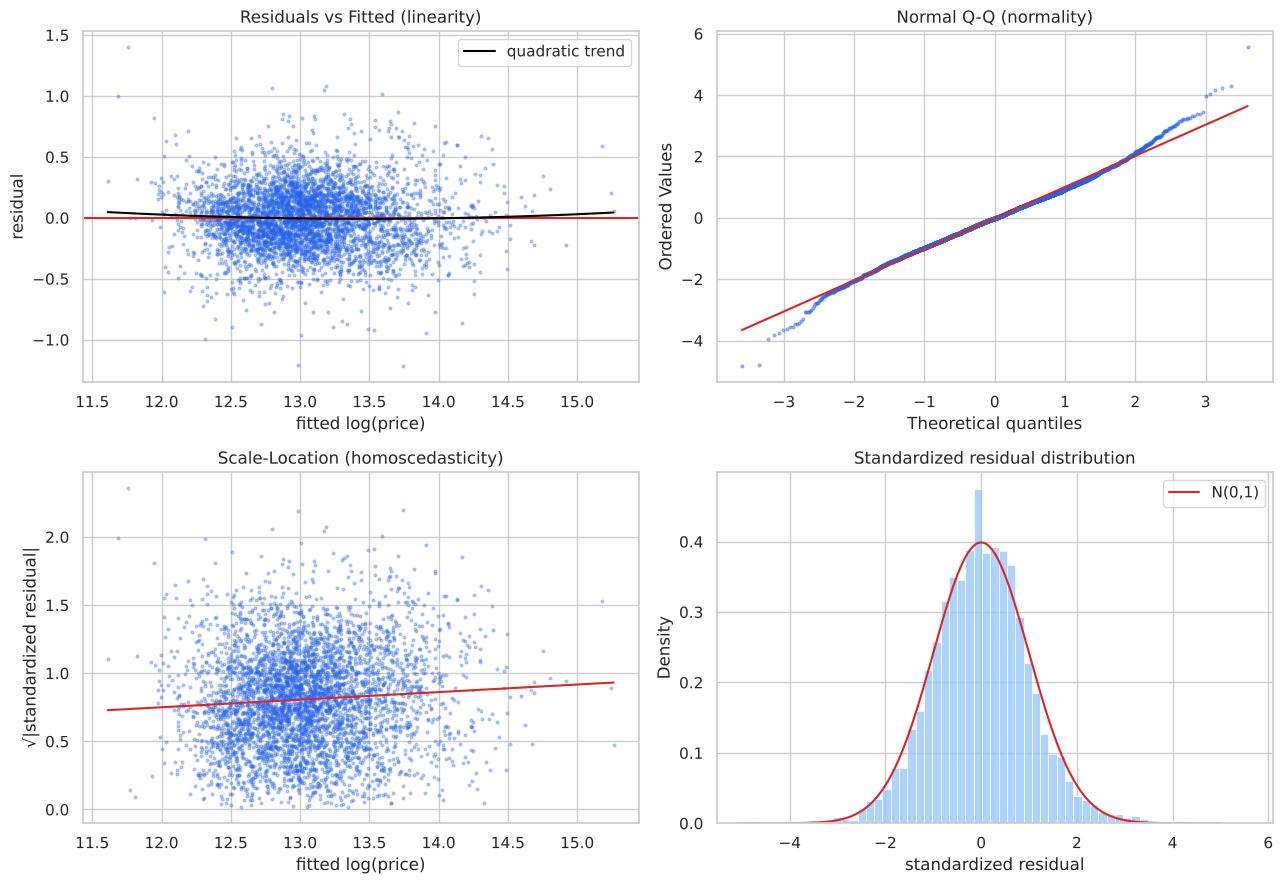

In [25]:
res_te = y_test - yhat_te
std_res = res_te / np.sqrt(ols.sigma2)
dw = np.sum(np.diff(ols.resid) ** 2) / np.sum(ols.resid ** 2)
jb_stat, jb_p = stats.jarque_bera(ols.resid)
print(f"Durbin-Watson = {dw:.3f}   Jarque-Bera = {jb_stat:.1f} (p = {jb_p:.2e})")
print(f"殘差偏態 = {stats.skew(ols.resid):.3f}，峰度 = {stats.kurtosis(ols.resid):.3f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ax = axes[0, 0]
ax.scatter(yhat_te, res_te, s=4, alpha=.3, color=C_MAIN)
ax.axhline(0, color=C_ACC)
lo = np.polyfit(yhat_te, res_te, 2)
gx = np.linspace(yhat_te.min(), yhat_te.max(), 100)
ax.plot(gx, np.polyval(lo, gx), color="black", lw=1.5, label="quadratic trend")
ax.set(title="Residuals vs Fitted (linearity)", xlabel="fitted log(price)", ylabel="residual")
ax.legend()
ax = axes[0, 1]
stats.probplot(std_res, dist="norm", plot=ax)
ax.get_lines()[0].set(markersize=2, alpha=.4, color=C_MAIN)
ax.get_lines()[1].set(color=C_ACC)
ax.set_title("Normal Q-Q (normality)")
ax = axes[1, 0]
ax.scatter(yhat_te, np.sqrt(np.abs(std_res)), s=4, alpha=.3, color=C_MAIN)
lo = np.polyfit(yhat_te, np.sqrt(np.abs(std_res)), 1)
ax.plot(gx, np.polyval(lo, gx), color=C_ACC, lw=1.5)
ax.set(title="Scale-Location (homoscedasticity)", xlabel="fitted log(price)", ylabel="√|standardized residual|")
ax = axes[1, 1]
sns.histplot(std_res, bins=60, stat="density", ax=ax, color=C_BAND)
gx2 = np.linspace(-5, 5, 200)
ax.plot(gx2, stats.norm.pdf(gx2), color=C_ACC, label="N(0,1)")
ax.set(title="Standardized residual distribution", xlabel="standardized residual")
ax.legend()
plt.tight_layout()
savefig("10_residual_diagnostics.png")

### 5.3 離群值與影響點診斷 (Outlier & Influence Diagnostics)

- **槓桿值 hᵢᵢ**：X(XᵀX)⁻¹Xᵀ 的對角線，代表該筆特徵組合有多「特殊」；門檻 2p/n。
- **學生化殘差 rᵢ** = eᵢ / (σ̂√(1−hᵢᵢ))；|rᵢ| > 3 視為離群值。
- **Cook's distance Dᵢ** = rᵢ²/p · hᵢᵢ/(1−hᵢᵢ)²，同時考慮殘差與槓桿；門檻 4/n。
- **測試集誤差百分比**：|實際 − 預測| / 實際，看多少比例的房屋誤差在 ±10%、±20% 以內。

In [26]:
X1_tr = np.column_stack([np.ones(len(X_train)), X_train[SELECTED].values])
lev = np.einsum("ij,jk,ik->i", X1_tr, ols.XtX_inv, X1_tr)
stud = ols.resid / np.sqrt(ols.sigma2 * (1 - lev))
cooks = stud ** 2 / ols.p * lev / (1 - lev) ** 2
n_tr = ols.n
lev_th, cook_th = 2 * ols.p / n_tr, 4 / n_tr
print(f"高槓桿點（h > {lev_th:.4f}）：{(lev > lev_th).sum()} 筆（{(lev > lev_th).mean():.1%}）")
print(f"離群值（|學生化殘差| > 3）：{(np.abs(stud) > 3).sum()} 筆（{(np.abs(stud) > 3).mean():.2%}）")
print(f"高影響點（Cook's D > {cook_th:.5f}）：{(cooks > cook_th).sum()} 筆（{(cooks > cook_th).mean():.1%}）")
print(f"最大 Cook's D = {cooks.max():.4f}（遠小於 1，沒有單一房屋會主導模型）")

# 影響最大的 5 筆
infl = d.loc[X_train.index, ["price", "sqft_living", "grade", "bedrooms", "waterfront", "view", "yr_built",
                             "zipcode"]].copy()
infl["pred_price"] = np.exp(ols.fitted).round(0)
infl["stud_resid"], infl["leverage"], infl["cooks_d"] = stud, lev, cooks
top_infl = infl.sort_values("cooks_d", ascending=False).head(5)
top_infl.to_csv(os.path.join(OUT_DIR, "top_influential_points.csv"))

# 敏感度：移除高影響點後重配，看係數與測試表現是否改變
keep = cooks <= cook_th
ols_rob = OLS().fit(X_train[SELECTED][keep], y_train[keep])
pte_rob = ols_rob.predict(X_test[SELECTED])
pp_rob = to_price(pte_rob, ols_rob.resid)
pp_m3 = to_price(ols.predict(X_test[SELECTED]), ols.resid)
print(f"移除 {(~keep).sum()} 筆高影響點後：Test R² {r2_score(y_test, ols.predict(X_test[SELECTED])):.4f} → "
      f"{r2_score(y_test, pte_rob):.4f}；Test RMSE ${np.sqrt(mean_squared_error(p_test, pp_m3)):,.0f} → "
      f"${np.sqrt(mean_squared_error(p_test, pp_rob)):,.0f}")
coef_shift = (ols_rob.beta[1:] - ols.beta[1:]) / ols.se[1:]
print(f"係數最大變動 = {np.abs(coef_shift).max():.1f} 個標準誤（{SELECTED[np.abs(coef_shift).argmax()]}）")

# 測試集誤差百分比
pct_err = (pp_m3 - p_test) / p_test * 100
within10, within20 = np.mean(np.abs(pct_err) <= 10), np.mean(np.abs(pct_err) <= 20)
print(f"測試集誤差百分比：中位數 |誤差| = {np.median(np.abs(pct_err)):.1f}%，"
      f"±10% 內 {within10:.1%}，±20% 內 {within20:.1%}")
top_infl.round(4)

高槓桿點（h > 0.0014）：884 筆（5.1%）
離群值（|學生化殘差| > 3）：132 筆（0.76%）
高影響點（Cook's D > 0.00023）：979 筆（5.7%）
最大 Cook's D = 0.0136（遠小於 1，沒有單一房屋會主導模型）
移除 979 筆高影響點後：Test R² 0.7595 → 0.7597；Test RMSE $179,761 → $181,248
係數最大變動 = 2.5 個標準誤（floors）
測試集誤差百分比：中位數 |誤差| = 16.1%，±10% 內 32.6%，±20% 內 59.0%


,price,sqft_living,grade,bedrooms,waterfront,view,yr_built,zipcode,pred_price,stud_resid,leverage,cooks_d
18848,380000.0,1980,10,3,1,4,1984,98166,1164860.0,-4.4657,0.0081,0.0136
17474,540000.0,2600,8,3,1,4,1912,98146,1213989.0,-3.2297,0.0081,0.0072
11556,357000.0,2460,7,3,1,4,1955,98198,710707.0,-2.7449,0.0081,0.0051
11844,770000.0,2050,9,3,1,4,1930,98166,1492566.0,-2.6391,0.0085,0.0050
15668,1680000.0,5170,11,5,1,4,1998,98155,3194951.0,-2.5626,0.0082,0.0046


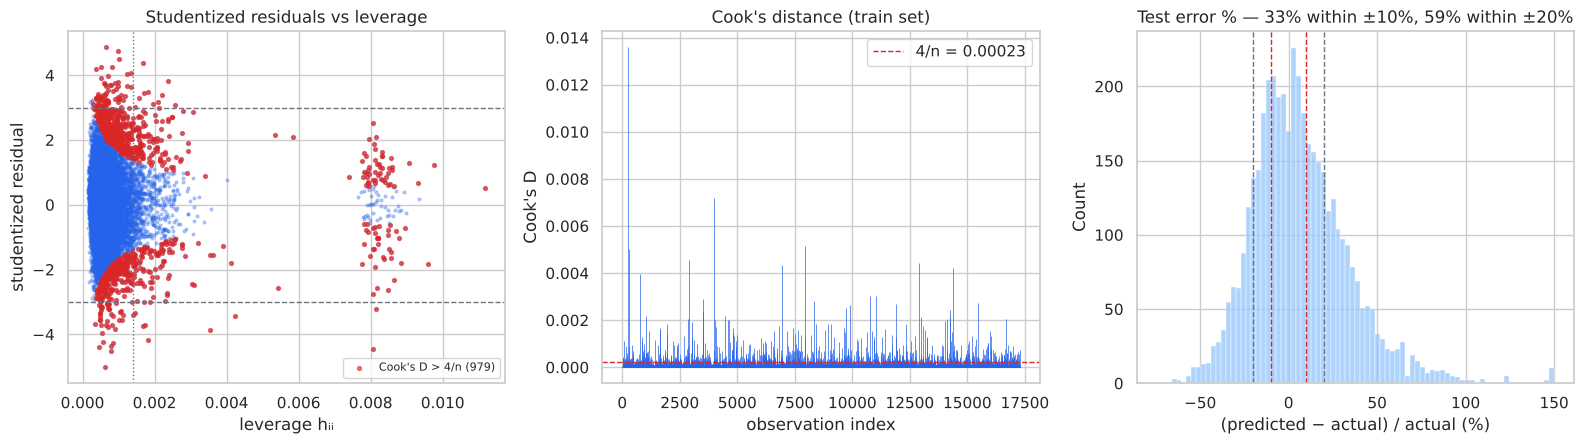

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
ax.scatter(lev, stud, s=4, alpha=.3, color=C_MAIN)
big = cooks > cook_th
ax.scatter(lev[big], stud[big], s=8, color=C_ACC, alpha=.6, label=f"Cook's D > 4/n ({big.sum()})")
ax.axhline(3, color=C_GREY, ls="--", lw=1)
ax.axhline(-3, color=C_GREY, ls="--", lw=1)
ax.axvline(lev_th, color=C_GREY, ls=":", lw=1)
ax.set(title="Studentized residuals vs leverage", xlabel="leverage hᵢᵢ", ylabel="studentized residual")
ax.legend(loc="lower right", fontsize=8)
ax = axes[1]
ax.vlines(np.arange(n_tr), 0, cooks, color=C_MAIN, lw=.5)
ax.axhline(cook_th, color=C_ACC, ls="--", lw=1, label=f"4/n = {cook_th:.5f}")
ax.set(title="Cook's distance (train set)", xlabel="observation index", ylabel="Cook's D")
ax.legend()
ax = axes[2]
sns.histplot(np.clip(pct_err, -100, 150), bins=80, ax=ax, color=C_BAND)
for v in (-20, -10, 10, 20):
    ax.axvline(v, color=C_ACC if abs(v) == 10 else C_GREY, ls="--", lw=1)
ax.set(title=f"Test error % — {within10:.0%} within ±10%, {within20:.0%} within ±20%",
       xlabel="(predicted − actual) / actual (%)")
plt.tight_layout()
savefig("11_outlier_influence.png")

### 5.4 評估小結
- 五種特徵選擇演算法在 k ≥ 9 後 Test RMSE 都收斂到約 $178k–180k；Forward SFS 與 Exhaustive 在每個 k 選出的組合幾乎相同。
- 簡約選擇 k = 11（CV RMSE 與最小值差 < 0.002）：Test R² = 0.760，只比 18 個特徵少 0.003，Test RMSE 多約 1%。
- Train R² 0.772 / Test 0.760 / CV 0.772 三者接近，k = 11 → 18 時 Test RMSE 只再降約 $1,900 → **沒有過擬合懸崖**。
- 整體 F 檢定 F = 5,317（p < 0.001），11 個係數皆顯著；VIF 最高 4.14，無共線性問題。
- 95% 預測區間的測試集涵蓋率 94.4%，接近名目 95%。
- Durbin-Watson = 2.02；殘差近似常態但尾部較厚；最大 Cook's D = 0.014，移除 979 筆高影響點後 Test R² 幾乎不變 → 模型穩健。
- 測試集中位數誤差 16.1%，59% 的房屋誤差在 ±20% 以內；若要再提升，需加入地段資訊（見 5.5）。

### 5.5 與網路主流 / 更優解法比較

Kaggle 上此資料集常見的進一步做法：
- **M6 MLR + zipcode one-hot**：把 70 個郵遞區號做成虛擬變數，讓模型學到「地段溢價」，仍屬線性回歸。
- **M7 Gradient Boosting（樹模型）**：非線性模型，作為「線性模型上限」的參考，不是本作業主模型。

In [28]:
from sklearn.ensemble import HistGradientBoostingRegressor

zip_dum = pd.get_dummies(d["zipcode"].astype(str), prefix="zip", drop_first=True).astype(float)
Xz = pd.concat([d[SELECTED].astype(float), zip_dum], axis=1)
Xz_train, Xz_test = Xz.loc[X_train.index], Xz.loc[X_test.index]

def quick_eval(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    ptr, pte = model.predict(Xtr), model.predict(Xte)
    pp = to_price(pte, y_train - ptr)
    cv = cross_val_score(model, Xtr, y_train, cv=kf, scoring="r2").mean()
    return {"model": name, "k": Xtr.shape[1], "test_R2": r2_score(y_test, pte), "CV_R2_mean": cv,
            "RMSE_USD": np.sqrt(mean_squared_error(p_test, pp)),
            "MAPE_%": np.mean(np.abs(p_test - pp) / p_test) * 100}

better = pd.DataFrame([
    quick_eval(f"Main model: {MAIN}", LinearRegression(), X_train[SELECTED], X_test[SELECTED]),
    quick_eval("M6 MLR + zipcode one-hot", LinearRegression(), Xz_train, Xz_test),
    quick_eval("M7 HistGradientBoosting (ref.)", HistGradientBoostingRegressor(random_state=RANDOM_STATE),
               X_train, X_test),
]).set_index("model")
better.to_csv(os.path.join(OUT_DIR, "better_solutions.csv"))
better.round(4)

,k,test_R2,CV_R2_mean,RMSE_USD,MAPE_%
model,,,,,
Main model: OLS + Forward SFS,11,0.7595,0.7715,179760.6276,21.1601
M6 MLR + zipcode one-hot,80,0.8711,0.8779,128883.5992,14.3454
M7 HistGradientBoosting (ref.),18,0.9009,0.9011,121144.2449,12.1760


In [29]:
# M6 的 95% 預測區間涵蓋率
ols_z = OLS().fit(Xz_train, y_train)
_, lo_z, hi_z = ols_z.predict(Xz_test, interval="prediction")
print(f"M6 95% 預測區間涵蓋率：{np.mean((y_test >= lo_z) & (y_test <= hi_z)):.2%}，"
      f"平均寬度（log）：{np.mean(hi_z - lo_z):.3f}")

M6 95% 預測區間涵蓋率：93.94%，平均寬度（log）：0.721


## 6. Deployment

將模型與特徵清單存檔，並提供 `predict_price()`：輸入一間房子的條件，回傳預估價格與 95% 預測區間。

In [30]:
# 只存純數值陣列，任何環境都能載入（不依賴自訂類別）
bundle = {"features": SELECTED, "beta": ols.beta, "XtX_inv": ols.XtX_inv,
          "sigma2": ols.sigma2, "df_resid": ols.df_resid,
          "smearing": float(np.mean(np.exp(ols.resid)))}
joblib.dump(bundle, os.path.join(OUT_DIR, "house_price_model.joblib"))
bundle = joblib.load(os.path.join(OUT_DIR, "house_price_model.joblib"))   # 驗證可重新載入


def predict_price(house: dict, bundle=bundle, alpha=0.05):
    h = dict(house)
    year = h.get("sale_year", 2015)
    h.setdefault("sale_year", year)
    h.setdefault("sale_month", 6)
    h["house_age"] = year - h.pop("yr_built", year - h.get("house_age", 30))
    h["is_renovated"] = int(h.pop("yr_renovated", 0) > 0) if "is_renovated" not in h else h["is_renovated"]
    h["has_basement"] = int(h.pop("sqft_basement", 0) > 0) if "has_basement" not in h else h["has_basement"]
    for c in ["sqft_living", "sqft_lot", "sqft_living15", "sqft_lot15"]:
        if c in h:
            h["log_" + c] = np.log(h.pop(c))
    x1 = np.array([1.0] + [float(h[f]) for f in bundle["features"]])
    yh = x1 @ bundle["beta"]
    se = np.sqrt(bundle["sigma2"] * (1 + x1 @ bundle["XtX_inv"] @ x1))
    tc = stats.t.ppf(1 - alpha / 2, bundle["df_resid"])
    return {"median_price": float(np.exp(yh)),
            "mean_price": float(np.exp(yh) * bundle["smearing"]),
            f"PI_{int((1-alpha)*100)}%": (float(np.exp(yh - tc * se)), float(np.exp(yh + tc * se)))}


new_house = {"bedrooms": 3, "bathrooms": 2.25, "sqft_living": 2000, "sqft_lot": 6000,
             "floors": 2, "waterfront": 0, "view": 0, "condition": 3, "grade": 8,
             "sqft_basement": 0, "yr_built": 1995, "yr_renovated": 0,
             "lat": 47.60, "long": -122.20, "sqft_living15": 2000, "sqft_lot15": 6000,
             "sale_year": 2015, "sale_month": 6}
out = predict_price(new_house)
print("範例房屋預測：")
print(f"  預估價格（中位數）：${out['median_price']:,.0f}")
print(f"  95% 預測區間：${out['PI_95%'][0]:,.0f} ~ ${out['PI_95%'][1]:,.0f}")

範例房屋預測：
  預估價格（中位數）：$503,786
  95% 預測區間：$307,482 ~ $825,415


**部署方式**
- 模型檔 `results/house_price_model.joblib` 可由網頁後端（Flask / FastAPI / Streamlit）載入，提供線上估價。
- 輸出同時給出「點估計」與「95% 預測區間」，讓使用者理解估價的不確定性。
- 資料為 2014–2015 年成交，實際上線需以新成交資料定期重新訓練並監控誤差漂移。